# EDA

=== 1. 基本信息 ===
数据集维度: (1075, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1075 entries, 0 to 1074
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   uri               1075 non-null   object 
 1   artist_name       1075 non-null   object 
 2   track_name        1075 non-null   object 
 3   source            1075 non-null   object 
 4   track_id          1075 non-null   object 
 5   fetched_at        1075 non-null   object 
 6   null_response     1075 non-null   int64  
 7   duration_ms       1075 non-null   int64  
 8   time_signature    1075 non-null   int64  
 9   tempo             1075 non-null   float64
 10  key               1075 non-null   int64  
 11  mode              1075 non-null   int64  
 12  danceability      1075 non-null   float64
 13  energy            1075 non-null   float64
 14  loudness          1075 non-null   float64
 15  speechiness       1075 non-null   float64
 16  acoustic

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,1075.000000,1075.000000,1075.000000,1075.000000,1075.000000,1075.000000,1075.000000,1075.000000,1075.000000
mean,0.699045,0.664107,-6.101297,0.119958,0.294594,0.009768,0.168309,0.562979,121.711782
std,0.125279,0.153421,2.279970,0.106353,0.244912,0.055254,0.122102,0.209892,29.074000
min,0.169000,0.092400,-28.669000,0.024300,0.000039,0.000000,0.022800,0.039700,67.337000
25%,0.621500,0.572000,-7.281500,0.047050,0.091000,0.000000,0.096700,0.404000,97.633000
50%,0.715000,0.680000,-5.774000,0.079300,0.225000,0.000001,0.119000,0.563000,119.592000
75%,0.792500,0.772000,-4.516000,0.160500,0.458500,0.000113,0.199000,0.715000,139.995500
max,0.957000,0.975000,-1.065000,0.924000,0.979000,0.796000,0.842000,0.978000,215.908000


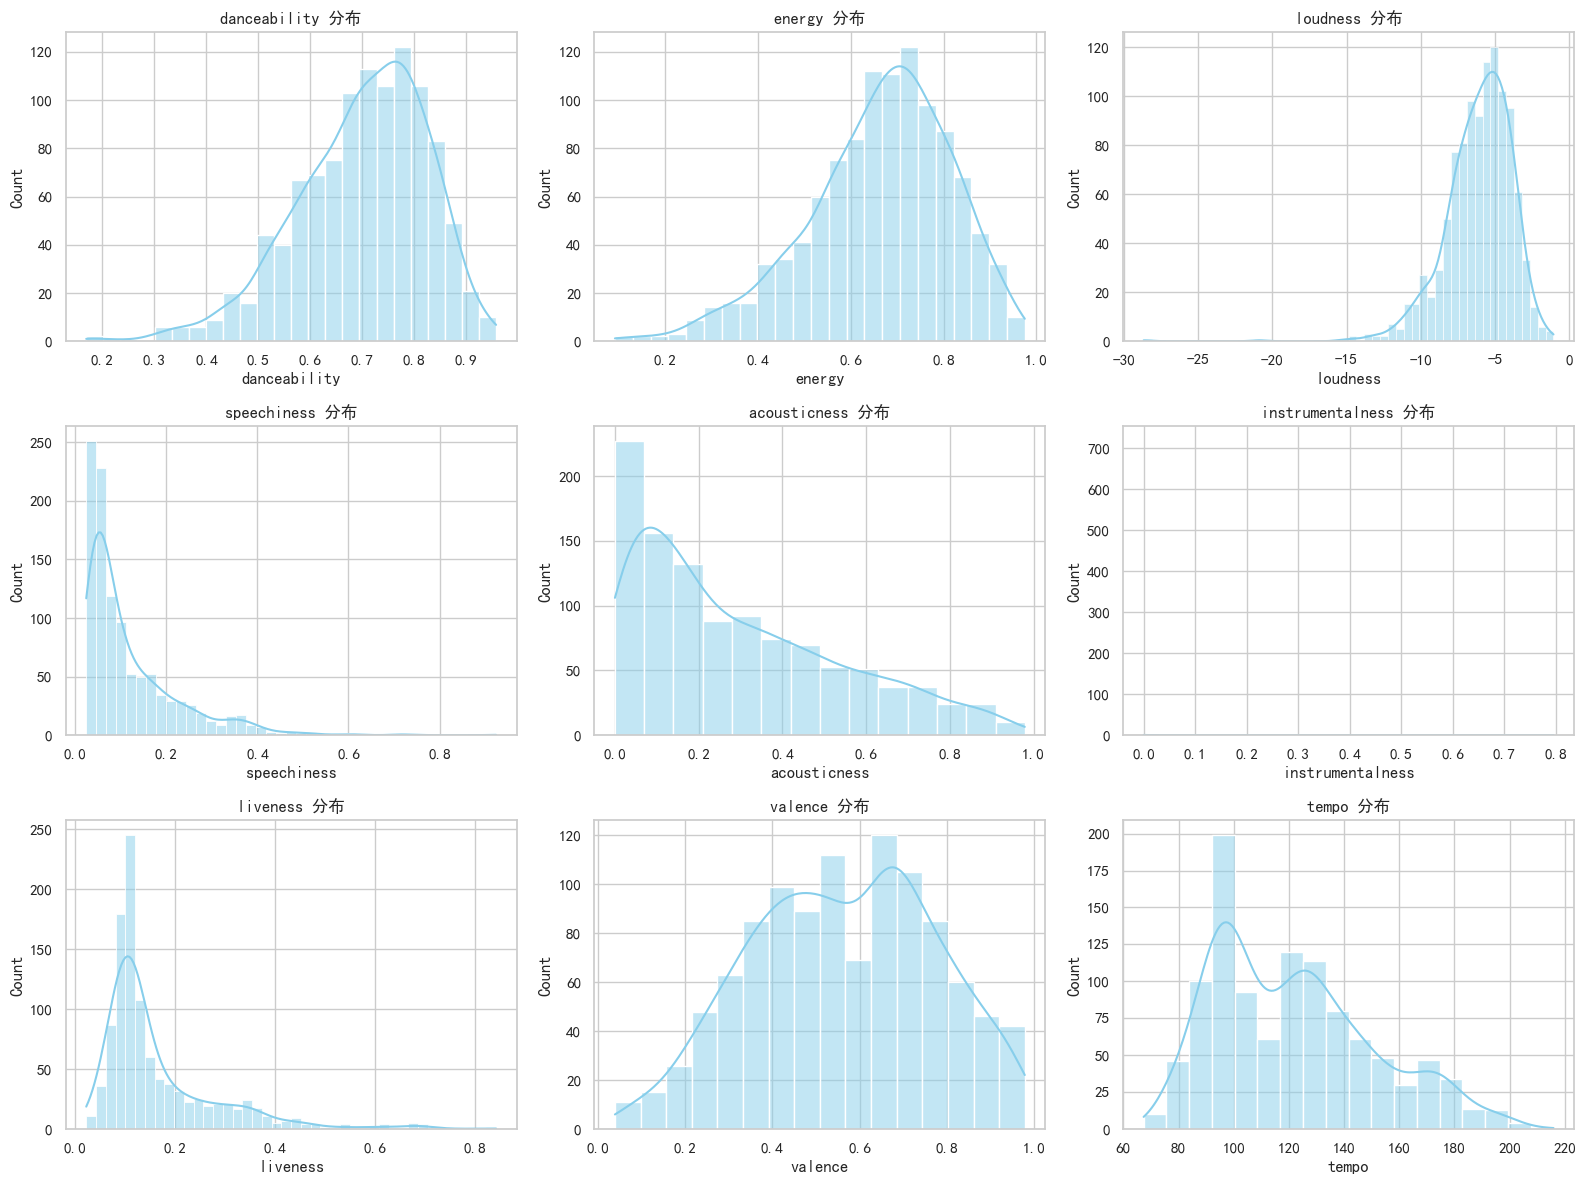


=== 3. 艺术家排名 (Top 15) ===


C:\Users\Luna_\AppData\Local\Temp\ipykernel_48300\4246776663.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_artists.values, y=top_artists.index, palette='viridis')


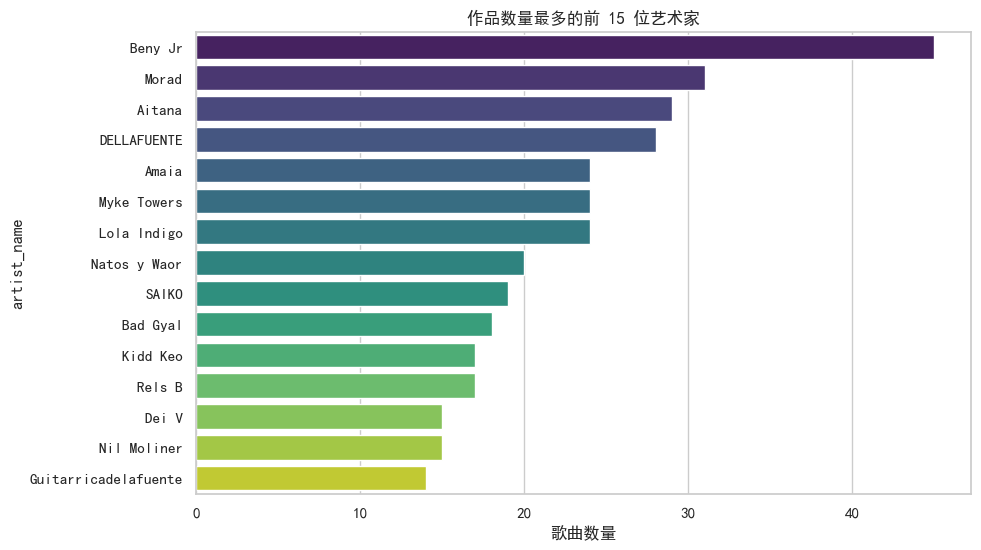


=== 4. 音频特征相关性分析 ===


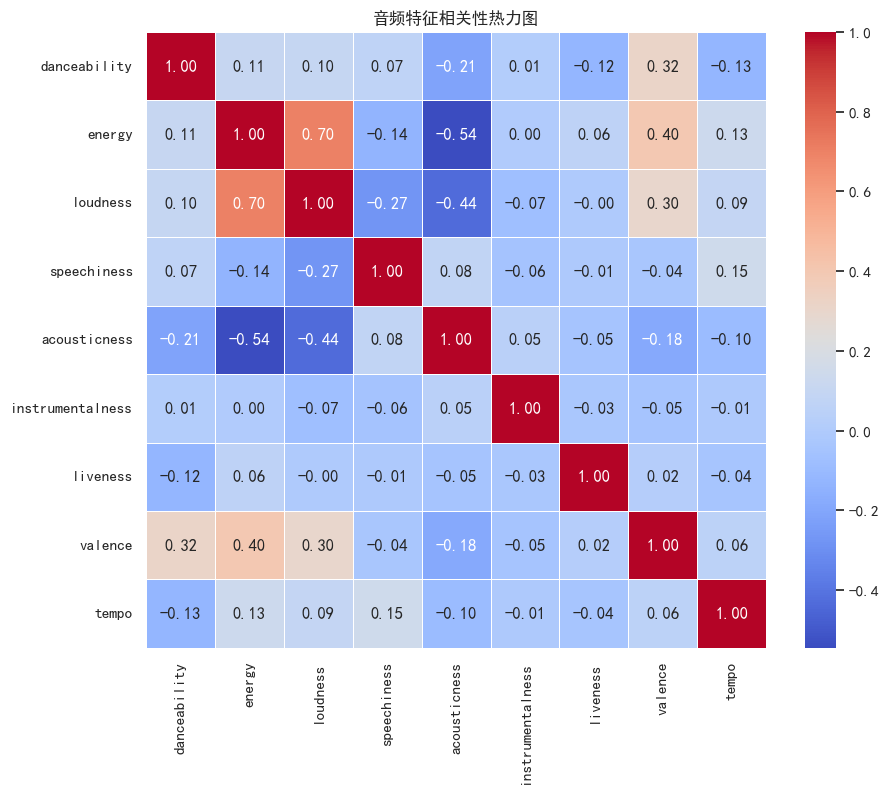


=== 5. 歌词长度分布 ===


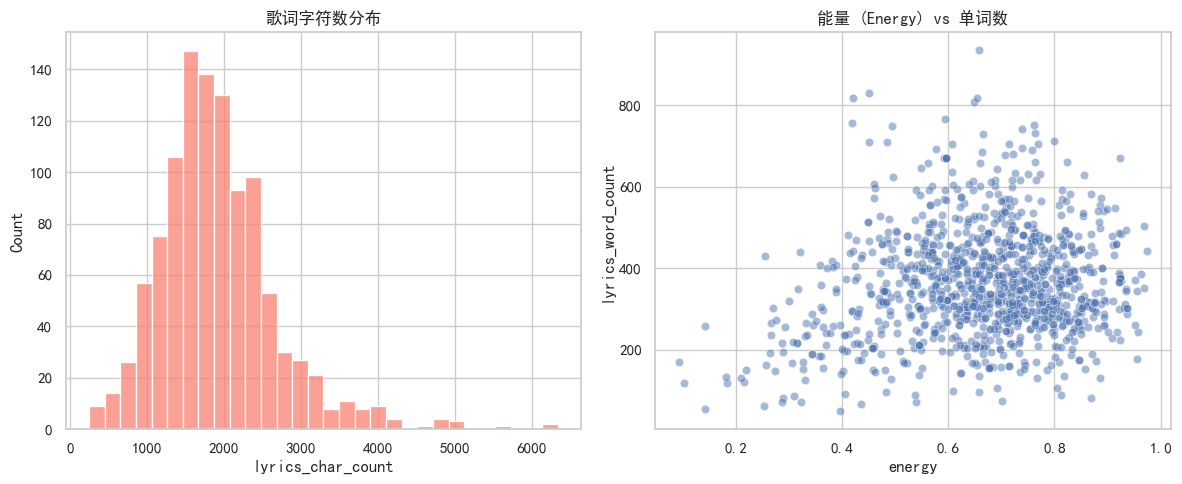


=== 6. 歌词词云预览 ===


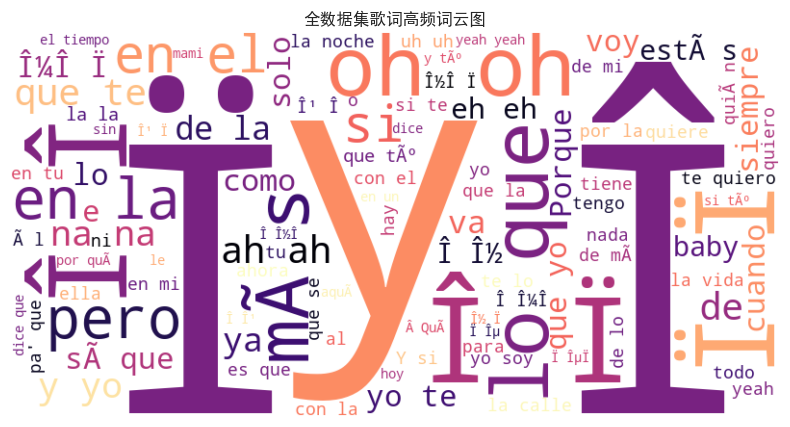

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Configuration & Setup
INPUT_FILE = '../Data/cleaned_data/cleaned_lyrics_data.csv'
OUTPUT_DIR = '../result/EDA'

# Create the output directory if it doesn't exist
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)
    print(f"Created directory: {OUTPUT_DIR}")

# Set visualization style
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

def run_eda():
    print(f"Starting EDA on {INPUT_FILE}...")
    
    # Load dataset
    try:
        df = pd.read_csv(INPUT_FILE)
    except FileNotFoundError:
        print(f"Error: {INPUT_FILE} not found. Please ensure the file is in the current directory.")
        return

    # --- 2. Data Overview & Summary Statistics ---
    print("Generating data summary...")
    summary = {
        "Shape": df.shape,
        "Columns": df.columns.tolist(),
        "Missing Values": df.isnull().sum().to_dict()
    }
    
    # Save descriptive statistics for numerical columns
    desc_stats = df.describe().transpose()
    desc_stats.to_csv(os.path.join(OUTPUT_DIR, 'summary_statistics.csv'))
    
    # --- 3. Audio Feature Distributions ---
    print("Plotting audio feature distributions...")
    audio_features = [
        'danceability', 'energy', 'loudness', 'speechiness', 
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
    ]
    
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    axes = axes.flatten()
    
    for i, col in enumerate(audio_features):
        sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
        axes[i].set_title(f'Distribution of {col}', fontsize=14)
    
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'audio_features_distribution.png'))
    plt.close()

    # --- 4. Correlation Heatmap ---
    print("Generating correlation heatmap...")
    plt.figure(figsize=(10, 8))
    corr = df[audio_features].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap of Audio Features', fontsize=16)
    plt.savefig(os.path.join(OUTPUT_DIR, 'correlation_heatmap.png'))
    plt.close()

    # --- 5. Artist Analysis (Top 15) ---
    print("Analyzing top artists...")
    plt.figure(figsize=(12, 7))
    top_artists = df['artist_name'].value_counts().head(15)
    sns.barplot(x=top_artists.values, y=top_artists.index, palette='magma')
    plt.title('Top 15 Artists by Number of Tracks', fontsize=16)
    plt.xlabel('Number of Tracks')
    plt.ylabel('Artist Name')
    plt.savefig(os.path.join(OUTPUT_DIR, 'top_15_artists.png'))
    plt.close()

    # --- 6. Lyric & Track Length Analysis ---
    print("Analyzing lyrics and track duration...")
    df['lyric_char_length'] = df['lyrics'].astype(str).apply(len)
    
    plt.figure(figsize=(12, 6))
    sns.histplot(df['lyric_char_length'], bins=50, color='salmon', kde=True)
    plt.title('Distribution of Lyric Character Length', fontsize=16)
    plt.xlabel('Character Count')
    plt.savefig(os.path.join(OUTPUT_DIR, 'lyrics_length_distribution.png'))
    plt.close()

    # --- 7. Emotional Mapping (Valence vs Energy) ---
    print("Generating emotional map...")
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=df, x='valence', y='energy', hue='danceability', size='danceability', palette='viridis', alpha=0.6)
    plt.title('Emotional Map: Valence (Mood) vs Energy', fontsize=16)
    plt.axhline(0.5, color='grey', linestyle='--')
    plt.axvline(0.5, color='grey', linestyle='--')
    plt.savefig(os.path.join(OUTPUT_DIR, 'valence_vs_energy_map.png'))
    plt.close()

    print(f"\nSUCCESS: EDA complete. All files saved to the '{OUTPUT_DIR}' folder:")
    print(f" - summary_statistics.csv")
    print(f" - audio_features_distribution.png")
    print(f" - correlation_heatmap.png")
    print(f" - top_15_artists.png")
    print(f" - lyrics_length_distribution.png")
    print(f" - valence_vs_energy_map.png")

if __name__ == "__main__":
    run_eda()